# Phase 6: festivals and outside data

Which outside factors move NECC egg prices, checked against 2009–2026 prices for the app's 7 zones:

1. A festival calendar for 2009–2027, computed from the Moon and the Sun and checked against published dates
2. Do festivals move prices?
3. Bird flu and COVID-19
4. Heat
5. Feed prices

Writes `Data/festival_calendar.csv` and `Data/festival_effects.csv`. Re-run `exploration.ipynb` afterwards to update the festival periods in the app. Weather and feed prices come from `python outside_data.py` (NASA POWER and the World Bank).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

import festivals
from eggdata import DATA, app_zones, zone_prices
from outside_data import read_feed, read_weather

prices = zone_prices()
zones = app_zones()
NAMES = dict(zip(zones.id, zones.name))
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
# Each day's price as % above or below the yearly average around it (a centred 365-day average).
level = 100 * (prices / prices.rolling(365, center=True, min_periods=300).mean() - 1)
week = pd.Series(np.minimum((prices.index.dayofyear - 1) // 7, 51), index=prices.index)
pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.dpi": 96, "axes.grid": True, "grid.alpha": 0.3})

## 1. Festival calendar

Lunar months run from new moon to new moon and take the name of the sign the Sun enters during the month, the rule panchangs use. Tamil and Malayalam months follow the Sun, and Ramzan follows the Islamic calendar. Below, computed first days are checked against dates published in panchangs and holiday lists.

In [ ]:
calendar = festivals.calendar()
calendar.to_csv(festivals.CALENDAR_PATH, index=False, date_format="%Y-%m-%d", lineterminator="\n")

PUBLISHED = {  # first days from published panchangs and holiday lists
    "navratri": ["2019-09-29", "2020-10-17", "2021-10-07", "2022-09-26", "2023-10-15", "2024-10-03", "2025-09-22"],
    "chaitra-navratri": ["2023-03-22", "2024-04-09", "2025-03-30"],
    "sawan": ["2023-07-04", "2024-07-22", "2025-07-11"],
    "ramzan": ["2019-05-07", "2020-04-25", "2021-04-14", "2022-04-03", "2023-03-24", "2024-03-12", "2025-03-02"],
    "karthika": ["2024-11-02", "2025-10-22"],
    "purattasi": ["2024-09-17", "2025-09-17"],
    "ayyappa": ["2024-11-16", "2025-11-17"],
    "sankranti": ["2025-01-13", "2026-01-13"],
}
starts = calendar.set_index(["event", "year"]).start
check = pd.DataFrame([(event, pd.Timestamp(day)) for event, days in PUBLISHED.items() for day in days],
                     columns=["event", "published"])
check["computed"] = [starts[(row.event, row.published.year)] for row in check.itertuples()]
check["days off"] = (check.computed - check.published).dt.days
print(f"Wrote {len(calendar)} festival dates; {(check['days off'] == 0).sum()} of {len(check)} published "
      "first days match exactly")
check.groupby("event")["days off"].agg(["count", "min", "max"])

Wrote 285 festival dates; 28 of 28 published first days match exactly


,count,min,max
event,,,
ayyappa,2,0,0
chaitra-navratri,3,0,0
karthika,2,0,0
navratri,7,0,0
purattasi,2,0,0
ramzan,7,0,0
sankranti,2,0,0
sawan,3,0,0


In [ ]:
upcoming = calendar[calendar.end >= prices.index.max()].sort_values("start").groupby("event").head(1)
upcoming.assign(
    name=upcoming.event.map(lambda event: festivals.EVENTS_BY_ID[event].name),
    days=(upcoming.end - upcoming.start).dt.days + 1,
)[["name", "start", "end", "days"]].set_index("name")

,start,end,days
name,,,
Kartik (North India),2026-10-27,2026-11-24,29
Karthika Masam,2026-11-10,2026-12-09,30
Ayyappa season,2026-11-17,2027-01-15,60
Winter,2026-12-01,2027-02-28,90
Christmas and New Year,2026-12-15,2027-01-01,18
Sankranti and Pongal,2027-01-14,2027-01-17,4
Ramzan,2027-02-09,2027-03-09,29
Summer heat,2027-04-01,2027-05-31,61
Chaitra Navratri (North India),2027-04-07,2027-04-15,9


## 2. Do festivals move prices?

The price level is each day's price as a % above or below the yearly average around it. For festivals whose dates move, a regression compares days inside the festival with the same weeks of the year in other years, so the usual yearly pattern is taken out. Each zone's festivals are estimated together, because some overlap (Sawan and Shravana, Kartik and Karthika). The COVID-19 crash (Feb–May 2020) and the 2021 bird flu are set aside. A second fit, one festival at a time, shows the 14 days before and after; adding those windows to the joint fit makes overlapping festivals swap effects, so the verdicts use the festival days only.

Festivals and seasons that fall on the same dates every year can't be separated from the yearly pattern. For those, the second table shows the usual level on their dates, as in the month bars.

In [ ]:
SHOCKS = {"COVID-19": ("2020-02-01", "2020-05-31"), "bird flu 2021": ("2021-01-04", "2021-02-28")}
flags = festivals.daily_flags(prices.index, calendar)
controls = pd.get_dummies(week, prefix="week", drop_first=True, dtype=float).join(pd.DataFrame(
    {name: ((prices.index >= start) & (prices.index <= end)).astype(float) for name, (start, end) in SHOCKS.items()},
    index=prices.index,
))


def nearby(event: str, before: bool, days: int = 14) -> pd.Series:
    """True in the `days` before (or after) each occurrence of `event`."""
    marked = pd.Series(False, index=prices.index)
    for row in calendar[calendar.event == event].itertuples():
        if before:
            marked.loc[row.start - pd.Timedelta(days=days):row.start - pd.Timedelta(days=1)] = True
        else:
            marked.loc[row.end + pd.Timedelta(days=1):row.end + pd.Timedelta(days=days)] = True
    return marked


def fit(zone: str, regressors: pd.DataFrame):
    """Price level on week-of-year and shock controls plus `regressors`, with errors allowing for slow drift."""
    data = sm.add_constant(controls.join(regressors.astype(float)))
    known = level[zone].notna()
    return sm.OLS(level[zone][known], data[known]).fit(cov_type="HAC", cov_kwds={"maxlags": 60})


rows = []
for zone in prices.columns:
    events = [event.id for event in festivals.EVENTS if event.moves and zone in event.zones]
    result = fit(zone, flags[events])
    interval = result.conf_int()
    rows += [{"zone": zone, "event": event, "effect": result.params[event], "low": interval.loc[event, 0],
              "high": interval.loc[event, 1], "p": result.pvalues[event]} for event in events]
during = pd.DataFrame(rows)


def with_stars(effect: float, p: float) -> str:
    return "" if np.isnan(effect) else f"{effect:+.1f}{'**' if p < 0.01 else '*' if p < 0.05 else ''}"


effect_table = during.pivot(index="event", columns="zone", values="effect")[list(prices.columns)]
p_table = during.pivot(index="event", columns="zone", values="p")[list(prices.columns)]
print("Price level during each festival vs the same weeks in other years (%); * p < 0.05, ** p < 0.01")
pd.DataFrame(
    {NAMES[zone]: [with_stars(effect_table.at[event, zone], p_table.at[event, zone]) for event in effect_table.index]
     for zone in effect_table.columns},
    index=[festivals.EVENTS_BY_ID[event].name for event in effect_table.index],
)

Price level during each festival vs the same weeks in other years (%); * p < 0.05, ** p < 0.01


,Chittoor,Chennai,Bengaluru,Namakkal,Kolkata,Vijayawada,Hyderabad
Chaitra Navratri (North India),+3.5*,+3.5*,+3.3*,+3.1*,+3.0*,+2.8,+2.4
Durga Puja,,,,,-2.1,,
Karthika Masam,-4.8**,,-4.5**,,,-3.9**,-3.7*
Kartik (North India),-4.8**,-5.0**,-5.2**,-4.7**,-5.7**,-6.3**,-5.8**
Navratri (North India),-2.3,-2.2,-2.6,-2.1,,-2.7,-3.4*
Ramzan,,,,,-1.8,,-2.0
Sawan (North India),-3.8*,-4.0**,-4.0**,-4.8**,-6.1**,-6.3**,-6.6**
Shravana,-6.4**,,-6.9**,,,-5.1**,-5.4**


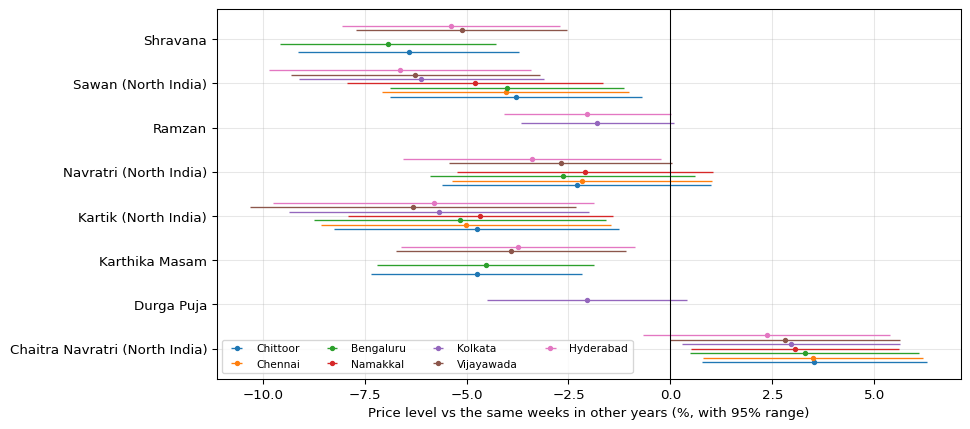

14 days before, during and 14 days after, one festival at a time, averaged over its zones (%)


,before,during,after
event,,,
Chaitra Navratri (North India),0.2,2.1,-2.6
Durga Puja,-1.7,-2.3,-4.5
Karthika Masam,-6.0,-5.4,4.1
Kartik (North India),-6.9,-11.4,-8.4
Navratri (North India),-0.5,-2.3,-3.5
Ramzan,-1.1,-1.9,-0.0
Sawan (North India),0.6,-7.6,-6.3
Shravana,-6.2,-12.0,-7.6


In [ ]:
events = list(effect_table.index)
fig, ax = plt.subplots(figsize=(10, 5))
for offset, zone in zip(np.linspace(-0.3, 0.3, len(prices.columns)), prices.columns):
    zone_rows = during[during.zone == zone].set_index("event").reindex(events)
    ax.errorbar(zone_rows.effect, np.arange(len(events)) + offset, fmt="o", ms=3, lw=1, label=NAMES[zone],
                xerr=[zone_rows.effect - zone_rows.low, zone_rows.high - zone_rows.effect])
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(events)), [festivals.EVENTS_BY_ID[event].name for event in events])
ax.set_xlabel("Price level vs the same weeks in other years (%, with 95% range)")
ax.legend(fontsize=8, ncol=4, loc="lower left")
plt.show()

rows = []
for zone in prices.columns:
    for event in [event.id for event in festivals.EVENTS if event.moves and zone in event.zones]:
        parts = pd.DataFrame({"before": nearby(event, before=True), "during": flags[event],
                              "after": nearby(event, before=False)})
        rows.append({"zone": zone, "event": event, **fit(zone, parts).params[["before", "during", "after"]]})
around = pd.DataFrame(rows)
print("14 days before, during and 14 days after, one festival at a time, averaged over its zones (%)")
around.groupby("event")[["before", "during", "after"]].mean().rename(
    index=lambda event: festivals.EVENTS_BY_ID[event].name).round(1)

In [ ]:
rows = []
for event in [event for event in festivals.EVENTS if not event.moves]:
    occurrences = calendar[calendar.event == event.id]
    for zone in event.zones:
        levels = pd.Series([level[zone].loc[row.start:row.end].mean() for row in occurrences.itertuples()]).dropna()
        median = levels.median()
        rows.append({"zone": zone, "event": event.id, "effect": median, "years": len(levels),
                     "same_sign": (np.sign(levels) == np.sign(median)).mean()})
fixed = pd.DataFrame(rows)
print("Usual price level on these dates, % vs the yearly average (median across years)")
fixed.pivot(index="event", columns="zone", values="effect")[list(prices.columns)].rename(
    index=lambda event: festivals.EVENTS_BY_ID[event].name, columns=NAMES).round(1)

Usual price level on these dates, % vs the yearly average (median across years)


zone,Chittoor,Chennai,Bengaluru,Namakkal,Kolkata,Vijayawada,Hyderabad
event,,,,,,,
Ayyappa season,8.5,8.3,10.5,8.8,NaN,13.6,13.5
Christmas and New Year,10.9,10.7,12.7,11.3,14.6,15.8,17.3
Purattasi,-2.3,-2.3,NaN,-1.3,NaN,NaN,NaN
Sankranti and Pongal,4.2,4.1,5.0,4.9,NaN,10.6,8.9
School summer holidays,-1.5,-1.5,-2.0,-2.4,NaN,-8.1,-7.0
Summer heat,-6.4,-6.3,-7.8,-7.0,-11.0,-11.8,-10.1
Winter,4.4,4.1,4.9,4.0,5.3,7.1,7.3


In [ ]:
def verdict(row: pd.Series) -> str:
    """Lower or higher when the effect is clear, otherwise unclear."""
    if row.kind == "moves":
        clear = row.p < 0.05 and abs(row.effect) >= 1
    else:
        clear = abs(row.effect) >= 2 and row.same_sign >= 0.7
    found = "lower" if row.effect < 0 else "higher"
    # A dated festival moving prices the opposite way to what people expect is treated as chance.
    if not clear or (row.kind == "moves" and found != festivals.EVENTS_BY_ID[row.event].expected):
        return "unclear"
    return found


effects = pd.concat([during.assign(kind="moves"), fixed.assign(kind="fixed")], ignore_index=True)
effects = effects.join(around.set_index(["zone", "event"])[["before", "after"]], on=["zone", "event"])
effects["verdict"] = effects.apply(verdict, axis=1)
columns = ["zone", "event", "kind", "effect", "low", "high", "p", "before", "after", "same_sign", "years", "verdict"]
effects[columns].round(3).to_csv(DATA / "festival_effects.csv", index=False, lineterminator="\n")
print("Verdicts written to Data/festival_effects.csv")
effects.pivot(index="event", columns="zone", values="verdict")[list(prices.columns)].rename(
    index=lambda event: festivals.EVENTS_BY_ID[event].name, columns=NAMES).fillna("")

Verdicts written to Data/festival_effects.csv


zone,Chittoor,Chennai,Bengaluru,Namakkal,Kolkata,Vijayawada,Hyderabad
event,,,,,,,
Ayyappa season,higher,higher,higher,higher,,higher,higher
Chaitra Navratri (North India),unclear,unclear,unclear,unclear,unclear,unclear,unclear
Christmas and New Year,higher,higher,higher,higher,higher,higher,higher
Durga Puja,,,,,unclear,,
Karthika Masam,lower,,lower,,,lower,lower
Kartik (North India),lower,lower,lower,lower,lower,lower,lower
Navratri (North India),unclear,unclear,unclear,unclear,,unclear,lower
Purattasi,lower,lower,,unclear,,,
Ramzan,,,,,unclear,,unclear


## 3. Bird flu and COVID-19

`Data/shocks.csv` lists dated shocks with a source. For each, the table shows how far the price level fell below its level in the week before (with the usual yearly pattern taken out), how many days that took, and how many days passed until it was back within 2%. The second table lists the largest unusual falls found in the data, whatever their cause.

fall (%)  \
Nationwide COVID-19 lockdown                       Chittoor         4.1   
                                                   Chennai          3.7   
                                                   Bengaluru       -4.2   
                                                   Namakkal         4.8   
                                                   Kolkata        -10.7   
                                                   Vijayawada      -6.4   
                                                   Hyderabad       -9.6   
Bird flu (H5N8) reported in Kerala, then 7 stat... Chittoor       -20.4   
                                                   Chennai        -20.0   
                                                   Bengaluru      -21.7   
                                                   Namakkal       -18.9   
                                                   Kolkata        -25.7   
                                                   Vijayawada     -27.2   
                                                   Hyderabad      -30.2   
Bird flu (H5N1) in ducks in Alappuzha, Kerala      Chittoor       -11.1   
                                                   Chennai        -10.9   
                                                   Bengaluru      -10.4   
                                                   Namakkal        -9.7   
                                                   Kolkata        -14.0   
                                                   Vijayawada     -10.9   
                                                   Hyderabad      -11.6   

                                                               days to lowest  \
Nationwide COVID-19 lockdown                       Chittoor             104.0   
                                                   Chennai              104.0   
                                                   Bengaluru            104.0   
                                                   Namakkal             104.0   
                                                   Kolkata                9.0   
                                                   Vijayawada           102.0   
                                                   Hyderabad            103.0   
Bird flu (H5N8) reported in Kerala, then 7 stat... Chittoor              24.0   
                                                   Chennai               24.0   
                                                   Bengaluru             10.0   
                                                   Namakkal              24.0   
                                                   Kolkata               10.0   
                                                   Vijayawada            10.0   
                                                   Hyderabad              8.0   
Bird flu (H5N1) in ducks in Alappuzha, Kerala      Chittoor              53.0   
                                                   Chennai               53.0   
                                                   Bengaluru             53.0   
                                                   Namakkal              50.0   
                                                   Kolkata               61.0   
                                                   Vijayawada            11.0   
                                                   Hyderabad             50.0   

                                                               days to recover  
Nationwide COVID-19 lockdown                       Chittoor              104.0  
                                                   Chennai               104.0  
                                                   Bengaluru             105.0  
                                                   Namakkal              104.0  
                                                   Kolkata                10.0  
                                                   Vijayawada            105.0  
                                                   Hyderabad  

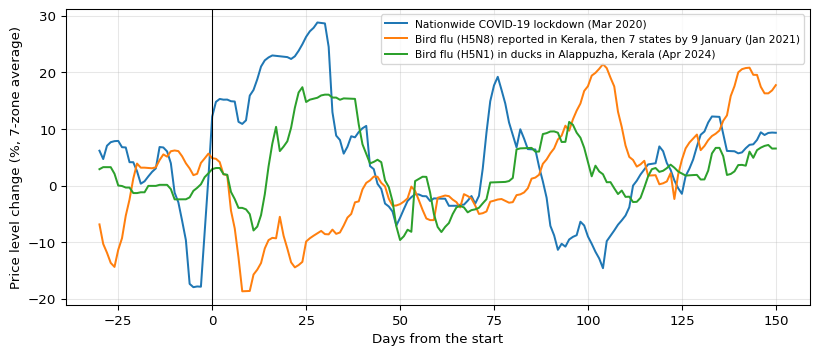

In [ ]:
abnormal = level - level.groupby(week).transform("mean")  # the price level with the usual yearly pattern taken out
shocks = pd.read_csv(DATA / "shocks.csv", parse_dates=["start"])


def shock_effect(zone: str, start: pd.Timestamp, days: int = 150) -> dict:
    before = abnormal[zone].loc[start - pd.Timedelta(days=7):start - pd.Timedelta(days=1)].mean()
    path = abnormal[zone].loc[start:start + pd.Timedelta(days=days)] - before
    lowest = path.idxmin()
    back = path.loc[lowest:] >= -2
    return {"fall (%)": path.min(), "days to lowest": (lowest - start).days,
            "days to recover": (back.idxmax() - start).days if back.any() else np.nan}


display(pd.DataFrame({(row.name, NAMES[zone]): shock_effect(zone, row.start)
                      for row in shocks.itertuples() for zone in prices.columns}).T.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
for row in shocks.itertuples():
    path = abnormal.loc[row.start - pd.Timedelta(days=30):row.start + pd.Timedelta(days=150)].mean(axis=1)
    ax.plot((path.index - row.start).days, path - path.iloc[:30].mean(), label=f"{row.name} ({row.start:%b %Y})")
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Days from the start", ylabel="Price level change (%, 7-zone average)")
ax.legend(fontsize=8)
plt.show()

In [ ]:
average = abnormal.mean(axis=1)
fall = average - average.shift(45)
drops = []
for day in fall.dropna().sort_values().index:
    if len(drops) == 10:
        break
    if all(abs((day - other).days) > 60 for other in drops):
        drops.append(day)
print("Largest unusual 45-day falls in the 7-zone price level")
pd.DataFrame([{"from about": average.loc[day - pd.Timedelta(days=45):day].idxmax().date(), "to": day.date(),
               "fall (% points)": fall[day]} for day in sorted(drops)]).round(1)

Largest unusual 45-day falls in the 7-zone price level


,from about,to,fall (% points)
0,2009-11-17,2009-12-26,-25.8
1,2011-01-15,2011-02-22,-26.9
2,2012-09-22,2012-11-06,-29.8
3,2016-07-30,2016-09-09,-27.6
4,2017-11-19,2018-01-01,-46.1
5,2018-07-30,2018-09-06,-35.3
6,2020-02-16,2020-03-19,-26.0
7,2020-04-22,2020-06-03,-29.5
8,2020-10-25,2020-12-09,-34.8
9,2025-12-23,2026-01-21,-25.1


## 4. Heat

Daily maximum temperature at each zone from NASA POWER. Do hotter-than-usual months show up in the price level in the same or later months? Correlations near 0 mean no link.

In [ ]:
weather = read_weather().pivot(index="date", columns="zone", values="tmax")[list(prices.columns)]
monthly_heat = weather.resample("MS").mean()
heat_anomaly = monthly_heat - monthly_heat.groupby(monthly_heat.index.month).transform("mean")
price_anomaly = abnormal.resample("MS").mean()
print("Correlation: the month's temperature anomaly vs the price level anomaly k months later")
display(pd.DataFrame({f"{lag} months later": {NAMES[zone]: heat_anomaly[zone].corr(price_anomaly[zone].shift(-lag))
                                              for zone in prices.columns} for lag in range(4)}).round(2))
hot_days = (weather >= 38).resample("MS").sum()
print("Days at 38 °C or more per month (average 2009–2026)")
hot_days.groupby(hot_days.index.month).mean().T.set_axis(MONTHS, axis=1).rename(index=NAMES).round(1)

Correlation: the month's temperature anomaly vs the price level anomaly k months later


,0 months later,1 months later,2 months later,3 months later
Chittoor,1.0e-02,-4.0e-02,-1.7e-01,-5.0e-02
Chennai,5.0e-02,-3.0e-02,-1.9e-01,-6.0e-02
Bengaluru,-1.0e-01,-1.2e-01,-1.2e-01,6.0e-02
Namakkal,-4.0e-02,-6.0e-02,-1.6e-01,-1.0e-02
Kolkata,-3.0e-02,9.0e-02,1.3e-01,1.6e-01
Vijayawada,-1.7e-01,-5.0e-02,-7.0e-02,1.3e-01
Hyderabad,-1.0e-01,2.0e-02,1.0e-02,1.3e-01


Days at 38 °C or more per month (average 2009–2026)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
zone,,,,,,,,,,,,
Chittoor,0.0,0.6,12.6,24.2,15.3,4.4,2.7,0.8,0.2,0.0,0.0,0.0
Chennai,0.0,0.0,0.4,4.5,6.7,2.1,0.8,0.1,0.0,0.0,0.0,0.0
Bengaluru,0.0,0.0,1.1,6.6,0.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Namakkal,0.0,1.6,17.4,19.8,7.7,1.3,1.0,1.1,0.8,0.2,0.0,0.0
Kolkata,0.0,0.0,3.9,20.6,12.8,2.4,0.0,0.0,0.0,0.0,0.0,0.0
Vijayawada,0.0,2.7,21.7,27.9,23.4,5.9,0.7,0.0,0.0,0.0,0.0,0.0
Hyderabad,0.0,0.4,10.9,23.7,24.1,4.6,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Feed prices

Monthly world maize and soybean meal prices from the World Bank (US$ per tonne). The file at this link ends in December 2024. Indian mandi prices from Agmarknet would be closer to farmers' costs but need a free data.gov.in API key, so they aren't used yet.

In [ ]:
feed = read_feed().set_index("month")
egg = prices.resample("MS").mean()
feed_year, egg_year = 100 * np.log(feed / feed.shift(12)), 100 * np.log(egg / egg.shift(12))
feed_quarter = 100 * np.log(feed / feed.shift(3))
print(f"World feed prices to {feed.index.max():%b %Y}")
print("12-month change in feed prices vs 12-month change in egg prices k months later (correlation)")
display(pd.DataFrame({f"{lag} months later": {
    f"{item} → {NAMES[zone]}": feed_year[item].corr(egg_year[zone].shift(-lag).reindex(feed.index))
    for item in feed.columns for zone in ("namakkal", "hyderabad", "kolkata")} for lag in (0, 3, 6, 12)}).round(2))
print("3-month change in feed prices vs the egg price level anomaly k months later (correlation)")
pd.DataFrame({f"{lag} months later": {
    f"{item} → {NAMES[zone]}": feed_quarter[item].corr(price_anomaly[zone].shift(-lag).reindex(feed.index))
    for item in feed.columns for zone in ("namakkal", "hyderabad", "kolkata")} for lag in (0, 1, 3, 6)}).round(2)

World feed prices to Dec 2024
12-month change in feed prices vs 12-month change in egg prices k months later (correlation)


,0 months later,3 months later,6 months later,12 months later
maize → Namakkal,1.0e-01,8.0e-02,7.0e-02,7.0e-02
maize → Hyderabad,-1.0e-02,-5.0e-02,-2.0e-02,9.0e-02
maize → Kolkata,1.4e-01,6.0e-02,7.0e-02,1.1e-01
soybean_meal → Namakkal,2.4e-01,1.9e-01,1.2e-01,-7.0e-02
soybean_meal → Hyderabad,2.8e-01,1.7e-01,8.0e-02,-8.0e-02
soybean_meal → Kolkata,3.8e-01,3.0e-01,1.8e-01,-5.0e-02


3-month change in feed prices vs the egg price level anomaly k months later (correlation)


,0 months later,1 months later,3 months later,6 months later
maize → Namakkal,3.0e-02,7.0e-02,-6.0e-02,6.0e-02
maize → Hyderabad,8.0e-02,1.1e-01,-5.0e-02,3.0e-02
maize → Kolkata,1.2e-01,1.3e-01,-5.0e-02,2.0e-02
soybean_meal → Namakkal,8.0e-02,1.1e-01,-0.0e+00,1.0e-02
soybean_meal → Hyderabad,8.0e-02,1.0e-01,-0.0e+00,2.0e-02
soybean_meal → Kolkata,9.0e-02,1.1e-01,1.0e-02,1.0e-02


## Findings (data to 26 Oct 2026)

- **Calendar:** all 28 published first days checked (Navratri, Chaitra Navratri, Sawan, Ramzan, Karthika, Purattasi, Ayyappa, Sankranti) match the computed dates exactly.
- **Festivals that clearly lower prices**, compared with the same weeks in other years:
  - Sawan: 4–7% lower in every zone
  - Kartik (North India): 5–6% lower in every zone
  - Shravana: 5–7% lower in Chittoor, Bengaluru, Vijayawada and Hyderabad
  - Karthika Masam: 4–5% lower in the same four zones

  In the one-at-a-time fits, prices start falling about two weeks before Shravana, Kartik and Karthika. They stay low for two weeks after Sawan, Shravana and Kartik.
- **No clear effect:** Navratri (only Hyderabad, −3%), Durga Puja (−2%), Ramzan (−2%, and people expect higher). Chaitra Navratri comes out 2–4% higher, the opposite of what people expect, so it's treated as chance.
- **Same dates every year** (these can't be told apart from the season):
  - summer: 6–12% below the yearly average
  - winter: 4–7% above
  - Christmas and New Year: 11–17% above
  - Ayyappa season: 8–14% above (it falls in the winter peak)
  - Purattasi: 1–2% below
- **Bird flu, January 2021:** prices fell 19–30% within 1–3½ weeks. They were back within 6 weeks in Chittoor, Chennai, Bengaluru and Kolkata, and within about 3 months in Namakkal, Vijayawada and Hyderabad. After the April 2024 Kerala duck outbreak, prices slid 10–14% over 7 weeks; the link is less certain.
- **COVID-19:** the crash started in mid-January 2020, weeks before the lockdown. Namakkal went from ₹443 on 5 January to ₹195 in the week to 22 March, which matches news reports at the time of rumours linking chicken to the virus. Prices bounced back once the lockdown began.
- **Other large unusual falls** (Nov 2017–Jan 2018, the largest; Jul–Sep 2018; Oct–Dec 2020; Dec 2025–Jan 2026) have no dated cause yet. Adding their causes to `Data/shocks.csv` would help.
- **Heat** at each zone shows no clear link with prices in the same or the next 3 months (correlations −0.19 to +0.16).
- **World feed prices** move with egg prices only loosely: 12-month soybean meal changes correlate 0.24–0.38 with egg changes in the same months, and less later. They don't help a 14-day forecast.
- **For Phase 8:** the moving festivals go into the models. Weather and world feed prices don't.